# 03 — Collision-free yield: reproducing IBM's model

> **Reproduction of a published model for research purposes.** Model, collision table and lattice layouts are from
> Hertzberg et al., *Laser-annealing Josephson junctions for yielding scaled-up superconducting quantum processors*,
> npj Quantum Information 7, 129 (2021), [arXiv:2009.00781](https://arxiv.org/abs/2009.00781), and its Supplementary Information.

**The problem.** Fixed-frequency transmons are wired together with cross-resonance gates. A gate works only if the
two qubits' frequencies sit in the right relation. If fabrication scatter pushes two frequencies onto one of seven
"collision" conditions (Table 1 of the paper), that gate's error goes above about 1%. A chip is *collision-free* only if
**no** pair or triple on it collides.

**The model (Sec. IV.3 of the paper).**
1. Give each qubit a design frequency from a 3- or 5-frequency pattern: f₁ = 5 GHz, equal steps.
2. Add Gaussian scatter σ_f to every qubit independently.
3. Count collisions. Repeat 1000 times. Yield = fraction of chips with zero collisions.
4. At each σ_f, use the frequency step that minimises collisions. The paper does not give the sweep range;
   we try 30–150 MHz in 5 MHz steps (our choice).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yieldkit.lattices import LATTICE_GRIDS, build_lattice
from yieldkit.collisions import COLLISION_TABLE, best_spacing_yield, fit_window, analytic_yield

pd.DataFrame([(c.number, c.condition, c.participants, None if c.bound_hz is None else c.bound_hz / 1e6)
              for c in COLLISION_TABLE], columns=["type", "condition", "qubits", "bound (± MHz)"])

,type,condition,qubits,bound (± MHz)
0,1,f_j01 = f_k01,"nearest neighbours j, k",17.0
1,2,f_j02 = 2 f_k01,"control j, target k",4.0
2,3,f_j01 = f_k12,"nearest neighbours j, k",30.0
3,4,f_k01 < f_j12 or f_j01 < f_k01,"control j, target k",NaN
4,5,f_i01 = f_k01,"j controls i and/or k, NN to both",17.0
5,6,f_i01 = f_k12 or f_i12 = f_k01,"j controls i and/or k, NN to both",25.0
6,7,f_j02 = f_k01 + f_i01,"j controls i and/or k, NN to both",17.0


## The three d = 5 lattices (Supplementary Figs 4, 5, 6)

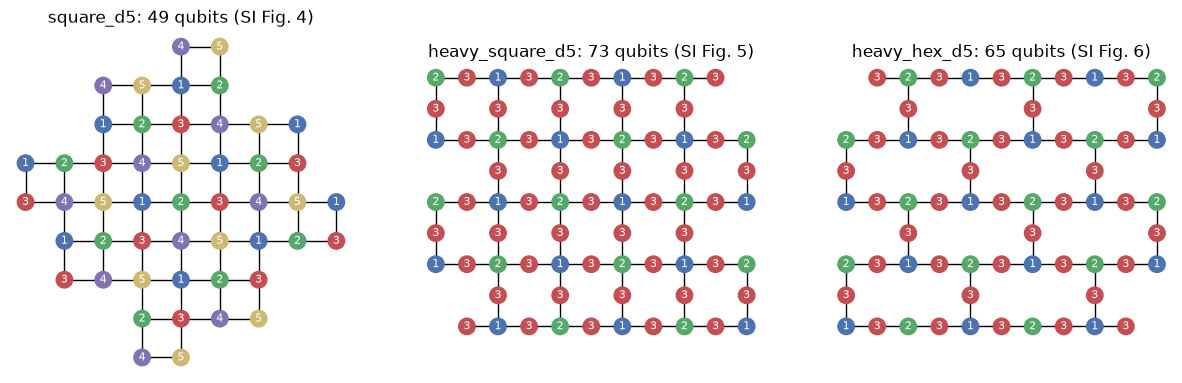

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = {1: "#4c72b0", 2: "#55a868", 3: "#c44e52", 4: "#8172b2", 5: "#ccb974"}
for ax, name in zip(axes, ["square_d5", "heavy_square_d5", "heavy_hex_d5"]):
    lat = build_lattice(name)
    for a, b in lat.edges:
        ax.plot(lat.col[[a, b]], -lat.row[[a, b]], "k-", lw=1, zorder=1)
    ax.scatter(lat.col, -lat.row, c=[colors[f] for f in lat.freq_index], s=140, zorder=2)
    for x, y, f in zip(lat.col, -lat.row, lat.freq_index):
        ax.text(x, y, str(f), ha="center", va="center", color="white", fontsize=8, zorder=3)
    ax.set_title(f"{name}: {lat.n_qubits} qubits (SI Fig. {lat.si_figure})"); ax.set_aspect("equal"); ax.axis("off")
plt.show()

## Yield and mean collisions vs frequency spread σ_f (like Fig. 4 of the paper)

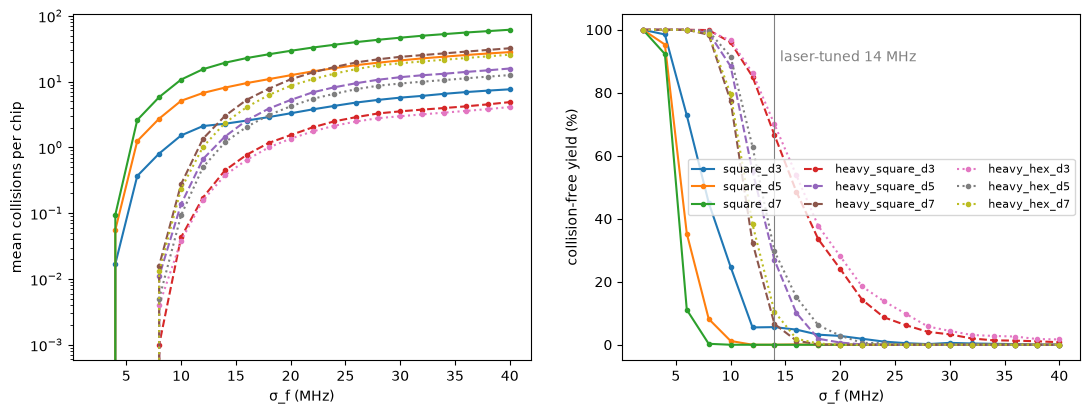

In [3]:
sigmas = np.arange(2e6, 41e6, 2e6)
rows = []
for name in LATTICE_GRIDS:
    lat = build_lattice(name)
    for s in sigmas:
        y, m, step = best_spacing_yield(lat, s, n_trials=1000, seed=0)
        rows.append(dict(lattice=name, n=lat.n_qubits, sigma_mhz=s / 1e6, yield_=y, mean_coll=m, step_mhz=step / 1e6))
sweep = pd.DataFrame(rows)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {"square": "-", "heavy_square": "--", "heavy_hex": ":"}
for name, g in sweep.groupby("lattice", sort=False):
    kind = name.rsplit("_", 1)[0]
    a1.plot(g.sigma_mhz, g.mean_coll, styles[kind], marker=".", label=name)
    a2.plot(g.sigma_mhz, 100 * g.yield_, styles[kind], marker=".", label=name)
a1.set_xlabel("σ_f (MHz)"); a1.set_ylabel("mean collisions per chip"); a1.set_yscale("log")
a2.set_xlabel("σ_f (MHz)"); a2.set_ylabel("collision-free yield (%)")
a2.axvline(14, color="grey", lw=0.8); a2.text(14.5, 90, "laser-tuned 14 MHz", color="grey")
a2.legend(fontsize=8, ncol=3)
plt.show()

## Side by side with Table 2 of the paper (σ_f = 14 MHz)

The paper's numbers are typed in from Table 2, and Δf is the paper's fitted window.
Our Δf is fitted to our own sweep with the same formula, Y = Φ(Δf/σ_f)^N. We fit log-yield over points with
yield ≥ 1%; the paper does not state its fitting method.

In [4]:
PAPER_TABLE2 = {  # Hertzberg et al. 2021, Table 2: (mean collisions, yield %, Delta_f MHz) at sigma_f = 14 MHz
    "square_d3": (3, 6, 13.96), "square_d5": (10, "<0.1", 13.23), "square_d7": (23, "<0.1", 12.12),
    "heavy_square_d3": (0.4, 67, 30.89), "heavy_square_d5": (1.5, 27, 29.49), "heavy_square_d7": (3.5, 6, 29.06),
    "heavy_hex_d3": (0.4, 70, 31.61), "heavy_hex_d5": (1.2, 33, 29.91), "heavy_hex_d7": (2.7, 8, 29.29),
}
table = []
for name in LATTICE_GRIDS:
    lat = build_lattice(name)
    y, m, step = best_spacing_yield(lat, 14e6, n_trials=1000, seed=0)
    g = sweep[sweep.lattice == name]
    dfit = fit_window(lat.n_qubits, g.sigma_mhz.to_numpy() * 1e6, g.yield_.to_numpy()) / 1e6
    pm, py, pdf = PAPER_TABLE2[name]
    table.append(dict(lattice=name, qubits=lat.n_qubits,
                      paper_mean_coll=pm, ours_mean_coll=round(m, 2),
                      paper_yield_pct=py, ours_yield_pct=round(100 * y, 1),
                      paper_delta_f=pdf, ours_delta_f=round(dfit, 2), our_step_mhz=step / 1e6))
pd.DataFrame(table)

,lattice,qubits,paper_mean_coll,ours_mean_coll,paper_yield_pct,ours_yield_pct,paper_delta_f,ours_delta_f,our_step_mhz
0,square_d3,17,3.0,2.29,6,5.6,13.96,15.66,65.0
1,square_d5,49,10.0,8.10,<0.1,0.0,13.23,13.38,55.0
2,square_d7,97,23.0,19.35,<0.1,0.0,12.12,12.04,50.0
3,heavy_square_d3,25,0.4,0.45,67,66.6,30.89,33.78,65.0
4,heavy_square_d5,73,1.5,1.46,27,26.9,29.49,29.38,65.0
5,heavy_square_d7,145,3.5,3.00,6,6.6,29.06,29.81,65.0
6,heavy_hex_d3,23,0.4,0.38,70,70.0,31.61,35.35,65.0
7,heavy_hex_d5,65,1.2,1.19,33,29.7,29.91,31.34,65.0
8,heavy_hex_d7,127,2.7,2.35,8,10.5,29.29,29.73,65.0


**Where we agree and where we differ.**
* The heavy lattices match Table 2's yields closely. The extra coupler qubits keep every control
  qubit's neighbours far apart in frequency.
* For the square lattices we also get ≈ 0% yield at d = 5 and 7, but **fewer mean collisions than the paper**.
  We cannot pin down why. The paper does not publish its exact counting rules (for example, how often a
  pair or triple is counted when several conditions apply), and our spacing sweep range is our own choice.
* The square d = 3 curve has a flat stretch near 12–14 MHz. That is where the collision-minimising step changes.
  Minimising *mean collisions* is not the same as maximising *yield*.
* Δf: same order as the paper (≈ 30 MHz heavy, ≈ 13 MHz square). Values differ in detail because the fitting method is unknown.

## Extrapolating with the fixed-window model (like Fig. 5)

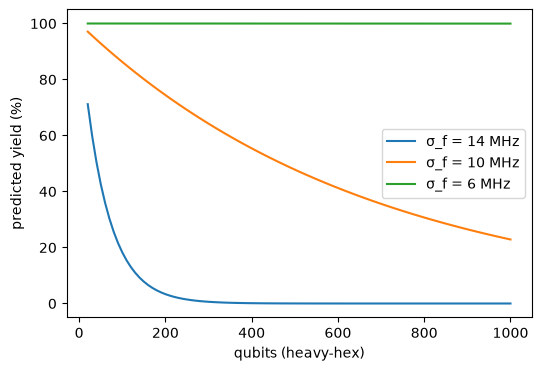

Our heavy-hex window Δf = 29.73 MHz; yield at 1000 qubits, 14 MHz: 0.000%


In [5]:
hh = sweep[sweep.lattice == "heavy_hex_d7"]
dfit = fit_window(127, hh.sigma_mhz.to_numpy() * 1e6, hh.yield_.to_numpy())
n = np.arange(20, 1001, 10)
fig, ax = plt.subplots(figsize=(6, 4))
for s in (14e6, 10e6, 6e6):
    ax.plot(n, [100 * analytic_yield(k, dfit, s) for k in n], label=f"σ_f = {s/1e6:.0f} MHz")
ax.set_xlabel("qubits (heavy-hex)"); ax.set_ylabel("predicted yield (%)"); ax.legend()
plt.show()
print(f"Our heavy-hex window Δf = {dfit/1e6:.2f} MHz; yield at 1000 qubits, 14 MHz: {100*analytic_yield(1000, dfit, 14e6):.3f}%")

## Bridge: what σ_f does our synthetic wafer (notebook 02) imply?

Hertzberg's model draws every qubit **independently**. On a real wafer, part of the variation is a smooth trend or a
per-die offset that moves all qubits on a chip **together**. Every Table 1 condition compares frequencies on the same
chip (anharmonicity is fixed), so a common shift cannot cause a collision. Below we report two numbers:

* **σ_f total**: the spread of f₀₁ across the whole wafer. This is what Hertzberg's 132.3 MHz measures.
* **σ_f within-die**: the spread of each qubit around its own die's mean, scaled by √(n/(n−1)) for n = 4 qubits per die.
  This is the part that can cause collisions.

We show each with our assumed 2% capacitance spread and with none, because that unpublished assumption turns out to matter.

In [6]:
from dataclasses import replace
from yieldkit.wafer import WaferConfig, make_wafer, RSD_LANG_2025, RSD_MODERN

hh3 = build_lattice("heavy_hex_d3")
bridge = []
for label, rsd in [("12.4% (Lang et al. 2025)", RSD_LANG_2025), ("~2% (as cited by Križan et al. 2026)", RSD_MODERN)]:
    for cq_rsd in (0.02, 0.0):
        _, truth = make_wafer(replace(WaferConfig(), rn_rsd=rsd, cq_rsd=cq_rsd), seed=2026)
        f = truth.f01_true_hz
        n = WaferConfig().qubits_per_die
        within = (f - truth.groupby(["wafer_id", "die_id"]).f01_true_hz.transform("mean")).std() * np.sqrt(n / (n - 1))
        total = f.std()
        bridge.append({"Rn spread": label, "Cq spread (assumption)": f"{100*cq_rsd:.0f}%",
                       "σ_f total (MHz)": round(total / 1e6, 1),
                       "heavy-hex d=3 yield, total": f"{100*best_spacing_yield(hh3, total, 1000, 0)[0]:.1f}%",
                       "σ_f within-die (MHz)": round(within / 1e6, 1),
                       "heavy-hex d=3 yield, within-die": f"{100*best_spacing_yield(hh3, within, 1000, 0)[0]:.1f}%"})
pd.DataFrame(bridge)

,Rn spread,Cq spread (assumption),σ_f total (MHz),"heavy-hex d=3 yield, total",σ_f within-die (MHz),"heavy-hex d=3 yield, within-die"
0,12.4% (Lang et al. 2025),2%,296.6,0.0%,151.8,0.0%
1,12.4% (Lang et al. 2025),0%,293.9,0.0%,145.2,0.0%
2,~2% (as cited by Križan et al. 2026),2%,63.2,0.1%,48.6,0.2%
3,~2% (as cited by Križan et al. 2026),0%,47.5,0.3%,23.3,15.0%


**Reading the bridge.**
* At Lang's 12.4% resistance spread, σ_f is hundreds of MHz. Collision-free yield is **0%** however you count it.
  This matches the paper's as-fabricated 132.3 MHz → ~0% result.
* At the ~2% spread, σ_f total ≈ 50 MHz without capacitance spread. That is consistent with the
  "±50 MHz" Križan et al. pair with 2%. Yield is still near 0% if every qubit varies independently.
* Only the within-die part matters for collisions. Without capacitance spread it gives a non-trivial yield, but adding our
  **assumed** 2% Cq spread brings it back to ~0%. The unpublished Cq spread is therefore one of the most important
  unknowns for a real fab. It is a number worth asking a partner for.
* Either way, as-fabricated chips are almost never collision-free. Choosing *which* dies to cool, and trimming
  them, is where the value is (Step 4).

**What this means for a fab.** As-fabricated spreads, such as the paper's 132 MHz, give essentially zero
collision-free chips at any useful size. Even after laser tuning to 14 MHz, yield falls quickly with qubit count.
Every MHz of frequency precision is worth a lot. That makes it worth predicting, *before cooldown*,
which dies are likely to be collision-free (notebook 04).